In [2]:
# ---- Setup: Drive + code + wandb (run this first, every session) ----
REPO_URL = "https://github.com/ammara-asif/fyp.git"   # <-- EDIT ONCE
BRANCH = "main"

import os, subprocess, sys
from google.colab import drive, userdata

# Drive must be mounted from the notebook kernel (never from a !python subprocess).
drive.mount("/content/drive")

# Code: fresh clone each session (Colab disk is wiped on reset), pull if it already exists.
# For a private repo, add a Colab secret GITHUB_TOKEN (a fine-grained read-only token).
CODE = "/content/fyp"
url = REPO_URL
try:
    tok = userdata.get("GITHUB_TOKEN")
    url = REPO_URL.replace("https://", f"https://{tok}@")
except Exception:
    pass
if os.path.isdir(CODE):
    subprocess.run(["git", "-C", CODE, "pull", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", "-b", BRANCH, url, CODE], check=True)
print(subprocess.check_output(["git", "-C", CODE, "log", "-1", "--oneline"]).decode())

# Dependencies (torch/torchvision come preinstalled with Colab's CUDA build; don't reinstall them).
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{CODE}/requirements.txt"], check=True)

# wandb: key comes from the Colab secret WANDB_API_KEY (key icon in the left sidebar). Never hardcode it.
import wandb
wandb.login(key=userdata.get("WANDB_API_KEY"))

sys.path.insert(0, f"{CODE}/src")
# Python caches imported modules for the whole kernel session, so after a git pull
# a plain `import` would silently keep running the OLD code. Drop the cached copies.
for _m in ["fyp_infra", "stage1_runner", "stage1_analysis"]:
    sys.modules.pop(_m, None)
import torch
from fyp_infra import setup_paths, run_sweep, run_id, load_result
import stage1_runner as sr
paths = setup_paths()   # -> /content/drive/MyDrive/fyp_nested_cl/{data,results,logs}
print(paths)
# Hard stop for training: a CPU run is ~12x slower and its timings are useless for budgeting.
REQUIRE_GPU = False   # analysis only: CPU runtime is fine
if REQUIRE_GPU:
    assert torch.cuda.is_available(), "No GPU! Runtime -> Change runtime type -> T4 GPU, then restart."
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU runtime)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
6bc9333 cpu/gpu flag



/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: ammara-asif125 (kashaf-saleem09-institute-of-business-administration) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


{'root': '/content/drive/MyDrive/fyp_nested_cl', 'data': '/content/drive/MyDrive/fyp_nested_cl/data', 'results': '/content/drive/MyDrive/fyp_nested_cl/results', 'logs': '/content/drive/MyDrive/fyp_nested_cl/logs', 'checkpoints': '/content/drive/MyDrive/fyp_nested_cl/checkpoints'}
GPU: none (CPU runtime)


In [3]:
import stage1_analysis as sa
TRAIN_RUNS = sa.list_runs(paths, stage="stage1_control")
for r in TRAIN_RUNS:
    c = r["config"]; print(r["run_id"], c["lr_schedule"], "lr", c["lr"], "seed", c["seed"])
ACFGS = sa.analysis_configs(TRAIN_RUNS)

32e5df8b8886 flat lr 0.3 seed 2
7b3073002436 flat lr 0.3 seed 0
bf6b7bf5e853 llrd lr 0.5 seed 2
bf7c7b91a468 llrd lr 0.5 seed 1
f686172d0a03 flat lr 0.3 seed 1
f7af3b7e79aa llrd lr 0.5 seed 0


In [4]:
out = run_sweep(ACFGS, sa.analyze_run, paths)

[1/6] fd82cb7878cb running
  checkpoint 1/20: task-IL on seen tasks 72.0%
  checkpoint 2/20: task-IL on seen tasks 54.3%
  checkpoint 3/20: task-IL on seen tasks 52.3%
  checkpoint 4/20: task-IL on seen tasks 41.8%
  checkpoint 5/20: task-IL on seen tasks 46.4%
  checkpoint 6/20: task-IL on seen tasks 45.2%
  checkpoint 7/20: task-IL on seen tasks 38.9%
  checkpoint 8/20: task-IL on seen tasks 44.6%
  checkpoint 9/20: task-IL on seen tasks 40.1%
  checkpoint 10/20: task-IL on seen tasks 32.8%
  checkpoint 11/20: task-IL on seen tasks 44.2%
  checkpoint 12/20: task-IL on seen tasks 35.9%
  checkpoint 13/20: task-IL on seen tasks 38.0%
  checkpoint 14/20: task-IL on seen tasks 38.6%
  checkpoint 15/20: task-IL on seen tasks 38.3%
  checkpoint 16/20: task-IL on seen tasks 33.4%
  checkpoint 17/20: task-IL on seen tasks 31.0%
  checkpoint 18/20: task-IL on seen tasks 32.9%
  checkpoint 19/20: task-IL on seen tasks 33.0%
  checkpoint 20/20: task-IL on seen tasks 31.7%
[2/6] c85bcec205d9 run

In [5]:
import numpy as np, pandas as pd
rows = []
for a in ACFGS:
    r = load_result(a, paths)
    if r is None: continue
    m = r["metrics"]; c = m["train_config"]
    row = {"arm": c["lr_schedule"], "lr": c["lr"], "seed": c["seed"],
           "til_final_avg_acc": m["til_final_avg_acc"], "til_avg_forgetting": m["til_avg_forgetting"]}
    for l, name in enumerate(m["level_modules"]):
        row[f"probe_final/{name}"] = m["probe_final_avg"][l]
        row[f"probe_forgetting/{name}"] = m["probe_forgetting"][l]
    rows.append(row)
adf = pd.DataFrame(rows)
display(adf)
summary = adf.drop(columns="seed").groupby(["arm", "lr"]).agg(["mean", "std", "count"])
display(summary.T)

,arm,lr,seed,til_final_avg_acc,til_avg_forgetting,probe_final/layer1,probe_forgetting/layer1,probe_final/layer3,probe_forgetting/layer3,probe_final/layer4,probe_forgetting/layer4
0,flat,0.3,2,31.70,52.968421,68.07,2.021053,79.45,6.368421,77.89,9.821053
1,flat,0.3,0,35.47,49.589474,65.05,2.400000,78.71,7.452632,77.49,10.389474
2,llrd,0.5,2,33.57,50.221053,69.97,1.526316,79.20,6.400000,77.33,8.736842
3,llrd,0.5,1,28.97,56.284211,69.35,0.252632,76.93,8.389474,74.64,11.547368
4,flat,0.3,1,33.91,51.652632,66.02,1.621053,78.01,6.736842,77.82,9.905263
5,llrd,0.5,0,35.55,48.852632,65.05,2.073684,79.47,6.136842,76.86,9.778947


arm                                 flat       llrd
lr                                   0.3        0.5
til_final_avg_acc       mean   33.693333  32.696667
                        std     1.894316   3.375816
                        count   3.000000   3.000000
til_avg_forgetting      mean   51.403509  51.785965
                        std     1.703193   3.955225
                        count   3.000000   3.000000
probe_final/layer1      mean   66.380000  68.123333
                        std     1.541850   2.679577
                        count   3.000000   3.000000
probe_forgetting/layer1 mean    2.014035   1.284211
                        std     0.389521   0.934355
                        count   3.000000   3.000000
probe_final/layer3      mean   78.723333  78.533333
                        std     0.720093   1.395075
                        count   3.000000   3.000000
probe_forgetting/layer3 mean    6.852632   6.975439
                        std     0.551302   1.231639
                        count   3.000000   3.000000
probe_final/layer4      mean   77.733333  76.276667
                        std     0.213620   1.436744
                        count   3.000000   3.000000
probe_forgetting/layer4 mean   10.038596  10.021053
                        std     0.306772   1.420819
                        count   3.000000   3.000000

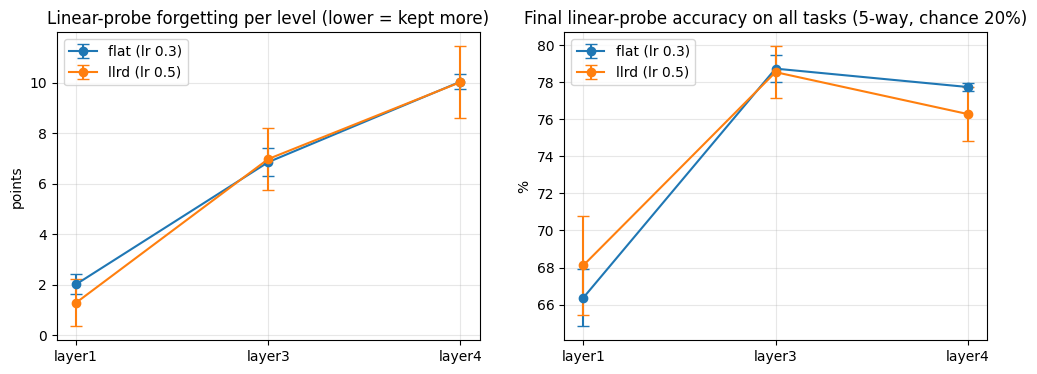

In [6]:
import matplotlib.pyplot as plt
levels = [k.split("/")[1] for k in adf.columns if k.startswith("probe_forgetting/")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (arm, lr), g in adf.groupby(["arm", "lr"]):
    lab = f"{arm} (lr {lr})"
    for ax, key in zip(axes, ["probe_forgetting", "probe_final"]):
        vals = g[[f"{key}/{l}" for l in levels]]
        ax.errorbar(levels, vals.mean(), yerr=vals.std(), marker="o", capsize=4, label=lab)
axes[0].set(title="Linear-probe forgetting per level (lower = kept more)", ylabel="points")
axes[1].set(title="Final linear-probe accuracy on all tasks (5-way, chance 20%)", ylabel="%")
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.show()